In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests

output = Path("calb05_results")
output.mkdir(exist_ok=True)
years = pd.Index(range(2000, 2025), name="Year")

def load_wdi(indicator, column_name):
    url = f"https://api.worldbank.org/v2/country/VNM/indicator/{indicator}"
    response = requests.get(
        url,
        params={
            "source": 2,
            "date": "2000:2024",
            "format": "json",
            "per_page": 100,
        },
        timeout=45,
    )
    response.raise_for_status()
    payload = response.json()
    if not isinstance(payload, list) or len(payload) < 2 or not payload[1]:
        raise ValueError(f"No World Bank data returned for {indicator}.")

    series = pd.Series(
        [row["value"] for row in payload[1]],
        index=[int(row["date"]) for row in payload[1]],
        name=column_name,
    )
    duplicate_rows = series.index.duplicated(keep=False).sum()
    print(f"{indicator} — rows with duplicate years: {duplicate_rows}")
    if duplicate_rows:
        raise ValueError(f"Check duplicate years for {indicator} before merging.")

    return series.reindex(years).rename_axis("Year")

all_years = pd.concat(
    [load_wdi("AG.CON.FERT.ZS", "x"), load_wdi("AG.YLD.CREL.KG", "y")],
    axis=1,
)
all_years.to_csv(output / "vietnam_wdi_2000_2024.csv")

missing_years = all_years.index[all_years.isna().any(axis=1)].tolist()
print("\nMissing observations by variable:")
print(all_years.isna().sum().to_string())
print("Years with missing data:", missing_years)

data = all_years.dropna().copy()
if data.empty:
    raise ValueError("No years have both indicators available.")

print(f"Complete observations: {len(data)}")
print(f"Years included: {data.index.min()}–{data.index.max()}")
display(data)

AG.CON.FERT.ZS — rows with duplicate years: 0
AG.YLD.CREL.KG — rows with duplicate years: 0

Missing observations by variable:
x    0
y    0
Years with missing data: []
Complete observations: 25
Years included: 2000–2024


,x,y
Year,,
2000,356.801660,4112.4
2001,286.734847,4167.3
2002,295.487576,4440.9
2003,332.929038,4506.7
2004,367.814360,4690.9
2005,339.648474,4726.2
2006,342.972117,4749.8
2007,403.517497,4846.2
2008,303.463430,4897.6


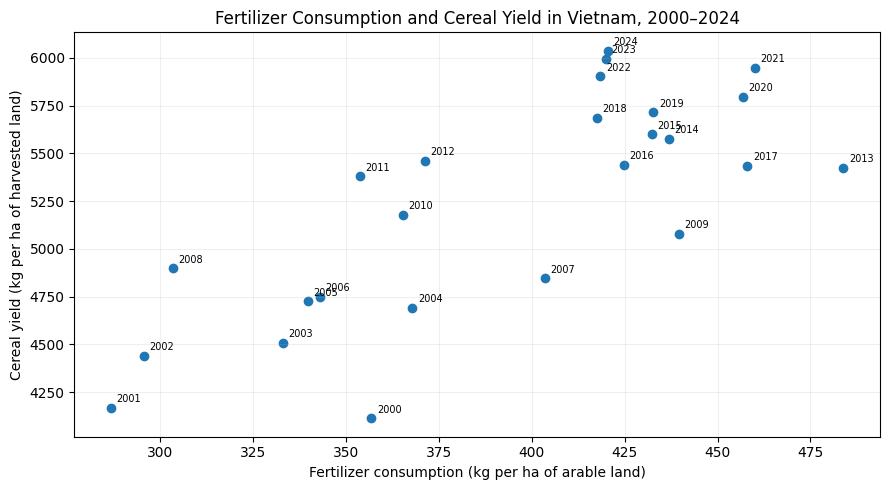

In [2]:
x_label = "Fertilizer consumption (kg per ha of arable land)"
y_label = "Cereal yield (kg per ha of harvested land)"

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(data["x"], data["y"], color="tab:blue")

for year, row in data.iterrows():
    ax.annotate(
        str(year), (row["x"], row["y"]),
        xytext=(4, 4), textcoords="offset points", fontsize=7,
    )

ax.set(
    xlabel=x_label,
    ylabel=y_label,
    title="Fertilizer Consumption and Cereal Yield in Vietnam, 2000–2024",
)
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(output / "01_scatter_plot.png", dpi=250)
plt.show()

In [3]:
def fit_quadratic(frame):
    if frame["x"].nunique() < 3:
        raise ValueError("At least three distinct x values are required.")
    c, b, a = np.polyfit(frame["x"], frame["y"], deg=2)
    return a, b, c

def predict(a, b, c, x):
    return a + b*x + c*x**2

def candidate_table(a, b, c, x_min, x_max):
    rows = [("Left endpoint", x_min), ("Right endpoint", x_max)]

    if c != 0:
        stationary_point = -b / (2*c)
        if x_min < stationary_point < x_max:
            label = "Interior maximum" if c < 0 else "Interior minimum"
            rows.append((label, stationary_point))

    table = pd.DataFrame(rows, columns=["Location", "Fertilizer consumption"])
    table["Predicted cereal yield"] = predict(
        a, b, c, table["Fertilizer consumption"]
    )
    return table

a, b, c = fit_quadratic(data)
x_min, x_max = data["x"].min(), data["x"].max()
candidates = candidate_table(a, b, c, x_min, x_max)
max_yield = candidates["Predicted cereal yield"].max()
maximizers = candidates[candidates["Predicted cereal yield"] == max_yield]

print(f"Fitted model: ŷ(x) = {a:.8g} {b:+.8g}x {c:+.8g}x²")
print(f"First derivative: ŷ′(x) = {b:.8g} {2*c:+.8g}x")
print(f"Observed range: [{x_min:.6f}, {x_max:.6f}]")

if c != 0:
    print(f"Stationary point: x* = {-b/(2*c):.6f}")
if b == 0 and c == 0:
    print("The model is constant over the observed range.")
elif "Interior maximum" not in candidates["Location"].values:
    print("There is no interior maximum within the observed range.")

print("\nCandidate points:")
display(candidates.round(6))
print("Location of the maximum predicted yield:")
display(maximizers.round(6))

data["Predicted cereal yield"] = predict(a, b, c, data["x"])
data["Residual"] = data["y"] - data["Predicted cereal yield"]

data.rename(columns={
    "x": "Fertilizer consumption",
    "y": "Observed cereal yield",
}).to_csv(output / "annual_data_and_residuals.csv")
candidates.to_csv(output / "candidate_points.csv", index=False)

Fitted model: ŷ(x) = -1873.7229 +29.241123x -0.027851082x²
First derivative: ŷ′(x) = 29.241123 -0.055702164x
Observed range: [286.734847, 483.857508]
Stationary point: x* = 524.954877
There is no interior maximum within the observed range.

Candidate points:


,Location,Fertilizer consumption,Predicted cereal yield
0,Left endpoint,286.734847,4220.897055
1,Right endpoint,483.857508,5754.371750


Location of the maximum predicted yield:


,Location,Fertilizer consumption,Predicted cereal yield
1,Right endpoint,483.857508,5754.37175


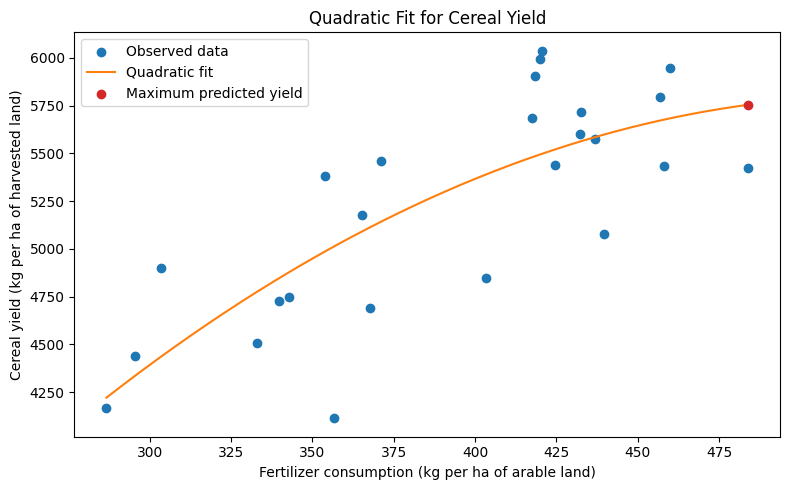

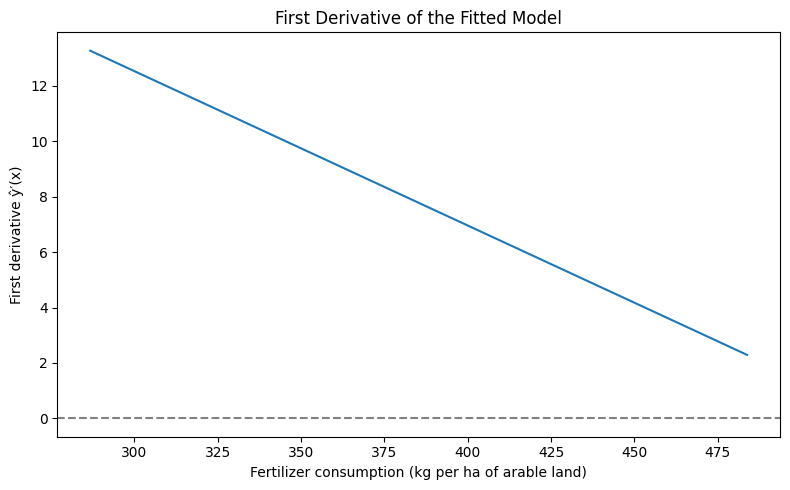

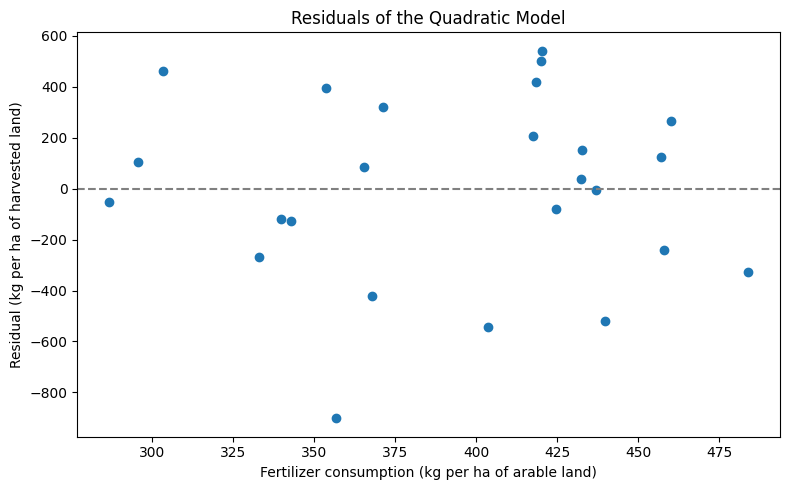

In [4]:
x_grid = np.linspace(x_min, x_max, 500)

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(data["x"], data["y"], label="Observed data")
ax.plot(x_grid, predict(a, b, c, x_grid), color="tab:orange",
        label="Quadratic fit")
ax.scatter(
    maximizers["Fertilizer consumption"],
    maximizers["Predicted cereal yield"],
    color="tab:red", zorder=3, label="Maximum predicted yield",
)
ax.set(xlabel=x_label, ylabel=y_label, title="Quadratic Fit for Cereal Yield")
ax.legend()
fig.tight_layout()
fig.savefig(output / "02_quadratic_fit.png", dpi=250)
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(x_grid, b + 2*c*x_grid)
ax.axhline(0, color="gray", linestyle="--")
ax.set(xlabel=x_label, ylabel="First derivative ŷ′(x)",
       title="First Derivative of the Fitted Model")
fig.tight_layout()
fig.savefig(output / "03_first_derivative.png", dpi=250)
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(data["x"], data["Residual"])
ax.axhline(0, color="gray", linestyle="--")
ax.set(xlabel=x_label, ylabel="Residual (kg per ha of harvested land)",
       title="Residuals of the Quadratic Model")
fig.tight_layout()
fig.savefig(output / "04_residual_plot.png", dpi=250)
plt.show()

In [5]:
print("Worked example from the assignment:")
example = candidate_table(2000, 20, -0.05, 50, 300)
display(example)

cases = [
    ("Worked example", 2000, 20, -0.05, 50, 300, 4000),
    ("Vietnam WDI data", a, b, c, x_min, x_max, max_yield),
]

for name, coef_a, coef_b, coef_c, lower, upper, analytical_yield in cases:
    search_grid = np.linspace(lower, upper, 10_001)
    predictions = predict(coef_a, coef_b, coef_c, search_grid)
    best_index = predictions.argmax()
    difference = abs(predictions[best_index] - analytical_yield)

    print(
        f"{name} — grid maximum at x = {search_grid[best_index]:.6f}, "
        f"predicted yield = {predictions[best_index]:.6f}, "
        f"absolute difference from the analytical result = {difference:.8g}"
    )

sensitivity_rows = []

# Refit after omitting one year at a time.
for year in data["Residual"].abs().nlargest(2).index:
    subset = data.drop(index=year)
    if subset["x"].nunique() < 3:
        print(f"Omitting {year} leaves too few distinct x values.")
        continue

    a_sub, b_sub, c_sub = fit_quadratic(subset)
    lower, upper = subset["x"].min(), subset["x"].max()
    subset_candidates = candidate_table(a_sub, b_sub, c_sub, lower, upper)
    best = subset_candidates.loc[subset_candidates["Predicted cereal yield"].idxmax()]

    sensitivity_rows.append({
        "Year omitted": year,
        "Original residual": data.loc[year, "Residual"],
        "Quadratic coefficient": c_sub,
        "Minimum x": lower,
        "Maximum x": upper,
        "Maximum location": best["Location"],
        "Fertilizer consumption at maximum": best["Fertilizer consumption"],
        "Maximum predicted cereal yield": best["Predicted cereal yield"],
    })

sensitivity = pd.DataFrame(sensitivity_rows)
sensitivity.to_csv(output / "sensitivity_analysis.csv", index=False)
print("\nSensitivity analysis for the two largest absolute residuals:")
display(sensitivity.round(6))

Worked example from the assignment:


,Location,Fertilizer consumption,Predicted cereal yield
0,Left endpoint,50.0,2875.0
1,Right endpoint,300.0,3500.0
2,Interior maximum,200.0,4000.0


Worked example — grid maximum at x = 200.000000, predicted yield = 4000.000000, absolute difference from the analytical result = 0
Vietnam WDI data — grid maximum at x = 483.857508, predicted yield = 5754.371750, absolute difference from the analytical result = 0

Sensitivity analysis for the two largest absolute residuals:


,Year omitted,Original residual,Quadratic coefficient,Minimum x,Maximum x,Maximum location,Fertilizer consumption at maximum,Maximum predicted cereal yield
0,2000,-901.508656,-0.039529,286.734847,483.857508,Interior maximum,477.016067,5669.655109
1,2007,-544.491110,-0.035629,286.734847,483.857508,Right endpoint,483.857508,5730.592596


In [6]:
from shutil import make_archive
from google.colab import files

archive = make_archive("CalB05_Results_EN", "zip", root_dir=output)
files.download(archive)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>